# Практическая работа №2: Исследование подгрупп сетей. Сети аффилированности.

Выполнил студент гр. 4385 Чечулин Денис Сергеевич. Вариант №2 (чётный).

## Цель работы

Овладеть навыками работы с математическими пакетами для исследования подгрупп в социальных сетях, а также моделирования, отображения и анализа сетей аффилированности.

## Постановка задачи

С помощью математических пакетов и соответствующих библиотек провести анализ заданных социальных сетей на предмет подгрупп. Провести исследование сети аффилированности CEO. Полученные результаты содержательно проинтерпретировать.

## Основные теоретические положения

**Подгруппа** — это подмножество акторов внутри сети, обладающее уникальными свойствами взаимодействия. Для поиска подгрупп используются различные алгоритмы (клики, k-ядра и т.д.).

**Точка сочленения (Cut vertex)** — это узел, при удалении которого сеть распадается на большее число компонент связности. По сути, это критически важные узлы, без которых сеть теряет целостность.

**Мост (Bridge)** — это ребро, при удалении которого сеть также распадается на большее число компонент связности.

**Централизация** — это характеристика всей сети в целом (в отличие от центральности отдельного узла). Она показывает, насколько сеть сконцентрирована вокруг одного или нескольких центральных акторов. Высокая централизация означает, что власть сосредоточена в руках одного узла (звездообразная сеть), низкая — что сеть распределена равномерно.

**k-ядро (k-core)** — это максимальное подмножество узлов, в котором каждый узел имеет степень (количество связей) не менее *k*. Например, 2-ядро — это узлы, у которых есть хотя бы 2 связи внутри этого ядра.

**Модулярность (Modularity)** — метрика, которая оценивает качество разбиения сети на сообщества. Значение модулярности показывает, насколько хорошо узлы сгруппированы в сообщества по сравнению со случайным графом. Хорошим считается значение от 0.3 до 0.7.

**Алгоритмы обнаружения сообществ (Community detection):**
*   *Edge-betweenness* — итеративно удаляет ребра с наибольшей посредничеством (наиболее важные мосты между сообществами).
*   *Leading eigenvector* — использует спектральный анализ матрицы модулярности для разделения сети.
*   *Fast-greedy* — жадный алгоритм, который на каждом шаге объединяет те сообщества, которые дают наибольший прирост модулярности.
*   *Spinglass* — физическая модель спинового стекла, где узлы "притягиваются" к своим сообществам.
*   *Walktrap* — основан на случайных блужданиях (чем чаще узлы встречаются при случайном блуждании, тем они ближе).
*   *Label propagation* — каждый узел принимает метку (сообщество) большинства своих соседей.
*   *InfoMAP* — минимизирует энтропию случайного блуждания (описание пути по сети с помощью кодов).
*   *Louvain* — итеративная оптимизация модулярности (очень быстрый и популярный).
*   *Optimal* — точный поиск максимальной модулярности (медленный, но самый точный).

**Сеть аффилированности (двудольная сеть / биграф)** — сеть, в которой акторы связаны не напрямую друг с другом, а через участие в общих событиях (или принадлежность к группам). Модальность такой сети равна 2 (два типа узлов: акторы и события).

**Матрица инцидентности** — матрица, где строки — это акторы (или события), а столбцы — события (или акторы). На пересечении стоит 1, если актор участвует в событии.

**Одномодальные проекции сети аффилированности:**
1.  *Сеть совместного участия (Co-membership)* — связывает акторов, если они участвовали в одних и тех же событиях. Вес ребра равен количеству общих событий.
2.  *Сеть перекрытия событий (Overlap)* — связывает события, если в них участвовали одни и те же акторы. Вес ребра равен количеству общих акторов.

**Степень участия актора** — количество событий, в которых он участвовал (в двудольном графе это его степень).

**Отношение шансов (Odds Ratio)** — статистический показатель, который показывает, во сколько раз шанс наступления события в одной группе выше, чем в другой. В контексте сетей используется для оценки силы связи между парами событий.

## Выполнение работы

**Задание 1.** Из файла `florentine_marital.csv` извлечь социоматрицу с помощью соответствующих функций. Отобразить сеть с помощью одного из алгоритмов укладки.

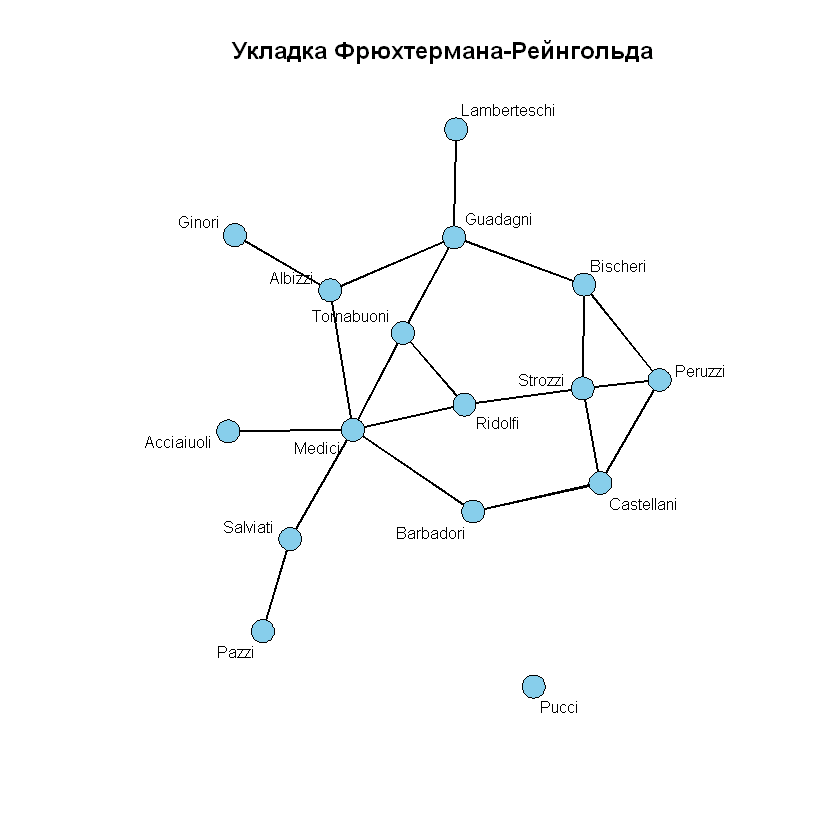

In [25]:
# Необходимые библиотеки
library(igraph) 
library(network)
library(sna)

# Извлечение социоматрицы из файла
network_raw <- read.csv("florentine_marital.csv", comment.char = "#", header = TRUE)
network_matrix <- as.matrix(network_raw)
rownames(network_matrix) <- colnames(network_matrix)

# Создание объекта сети
net <- network(network_matrix, directed = FALSE, matrix.type = "adjacency", ignore.eval = TRUE)

# Отображение сети
gplot(net, gmode = "graph", 
      mode = "fruchtermanreingold", 
      displaylabels = TRUE, 
      label.cex = 0.8, 
      vertex.col = "skyblue", 
      main = "Укладка Фрюхтермана-Рейнгольда")

**Задание 2.** Выявить точки сочленения и мосты сети. Подтвердить свои догадки с помощью соответствующих функций. Построить графики сети, на котором выделены точки сочленения и мосты.

Точки сочленения: Albizzi Guadagni Medici Salviati 

Мосты (пары вершин):
Albizzi - Ginori 
Guadagni - Lamberteschi 
Pazzi - Salviati 
Medici - Salviati 
Acciaiuoli - Medici 


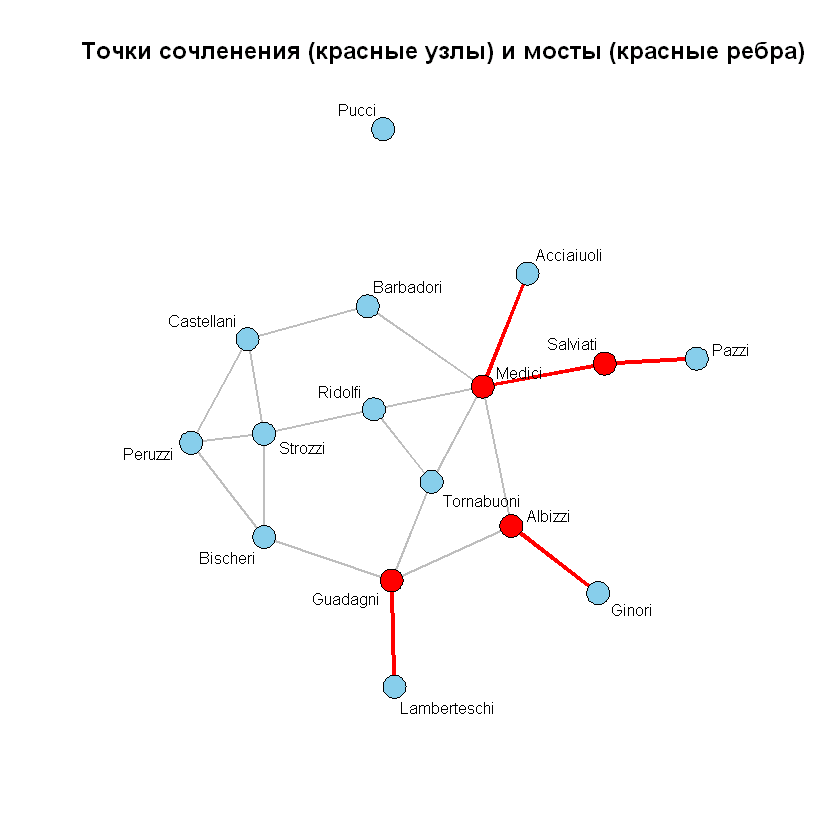

In [22]:
g_temp <- graph_from_adjacency_matrix(network_matrix, mode = "undirected")
br_edges <- bridges(g_temp)
el_ig <- as_edgelist(g_temp)

# Индексы точек сочленения
cp <- cutpoints(network_matrix)

# Результаты
cat("Точки сочленения:", rownames(network_matrix)[cp], "\n\n")

cat("Мосты (пары вершин):\n")
for (i in br_edges) 
{
  cat(el_ig[i, 1], "-", el_ig[i, 2], "\n")
}

# Подготовка к визуализации
v_colors <- rep("skyblue", 16)
v_colors[cp] <- "red"
el_sna <- as.edgelist(net)
e_colors <- rep("gray", nrow(el_sna))

# Мосты в красный цвет
for (i in br_edges) 
{
  v1_name <- el_ig[i, 1]
  v2_name <- el_ig[i, 2]
  for (j in 1:nrow(el_sna)) 
  {
    if ((rownames(network_matrix)[el_sna[j,1]] == v1_name && rownames(network_matrix)[el_sna[j,2]] == v2_name) ||
        (rownames(network_matrix)[el_sna[j,1]] == v2_name && rownames(network_matrix)[el_sna[j,2]] == v1_name)) 
    {
      e_colors[j] <- "red"
    }
  }
}

# График с выделением точек сочленения и мостов
gplot(net, gmode = "graph", 
      mode = "fruchtermanreingold",
      displaylabels = TRUE, 
      label.cex = 0.8,
      vertex.col = v_colors,
      edge.col = e_colors,
      edge.lwd = ifelse(e_colors == "red", 2.5, 1), 
      main = "Точки сочленения (красные узлы) и мосты (красные ребра)")

**Задание 3.** Вычислить значение централизации для каждой меры. Сделать выводы.

In [26]:
# Централизация по степени (Degree)
cent_degree <- centr_degree(g_ig, mode = "all", normalized = TRUE)$centralization

# Централизация по близости (Closeness)
cent_closeness <- centr_clo(g_ig, mode = "all", normalized = TRUE)$centralization

# Централизация по посредничеству (Betweenness)
cent_betweenness <- centr_betw(g_ig, directed = FALSE, normalized = TRUE)$centralization

# Вывод результатов
cat("Централизация по степени (Degree):", round(cent_degree, 4), "\n")
cat("Централизация по близости (Closeness):", round(cent_closeness, 4), "\n")
cat("Централизация по посредничеству (Betweenness):", round(cent_betweenness, 4), "\n")

Централизация по степени (Degree): 0.2333 
Централизация по близости (Closeness): NaN 
Централизация по посредничеству (Betweenness): 0.3835 


**Вывод:**
*   Централизация по степени (0.2333): Значение умеренное, что говорит о том, что сеть не является идеальной «звездой». Хотя семья Медичи имеет наибольшее число связей, другие семьи (например, Альбицци, Сальвиати) также имеют достаточно связей, чтобы не быть полностью зависимыми от одного центра.
*   Централизация по близости (NaN): Значение не определено из-за наличия изолированных вершин в графе (расстояние до некоторых семей равно бесконечности).
*   Централизация по посредничеству (0.3835): Это довольно высокий показатель. Он означает, что сеть сильно зависит от «посредников». Если убрать узел, через который проходит большинство кратчайших путей (а это, безусловно, Медичи), сеть распадется на несколько изолированных частей.

**Задание 4.** Исследовать данную сеть на предмет подгрупп с помощью 𝑘-ядер. Указать какие подгруппы получились. Сделать выводы.

Результаты разбиения на k-ядра:
Ядро 2 (размер 10): Albizzi, Barbadori, Bischeri, Castellani, Guadagni, Medici, Peruzzi, Ridolfi, Strozzi, Tornabuoni
Ядро 1 (размер 5): Acciaiuoli, Ginori, Lamberteschi, Pazzi, Salviati
Ядро 0 (размер 1): Pucci


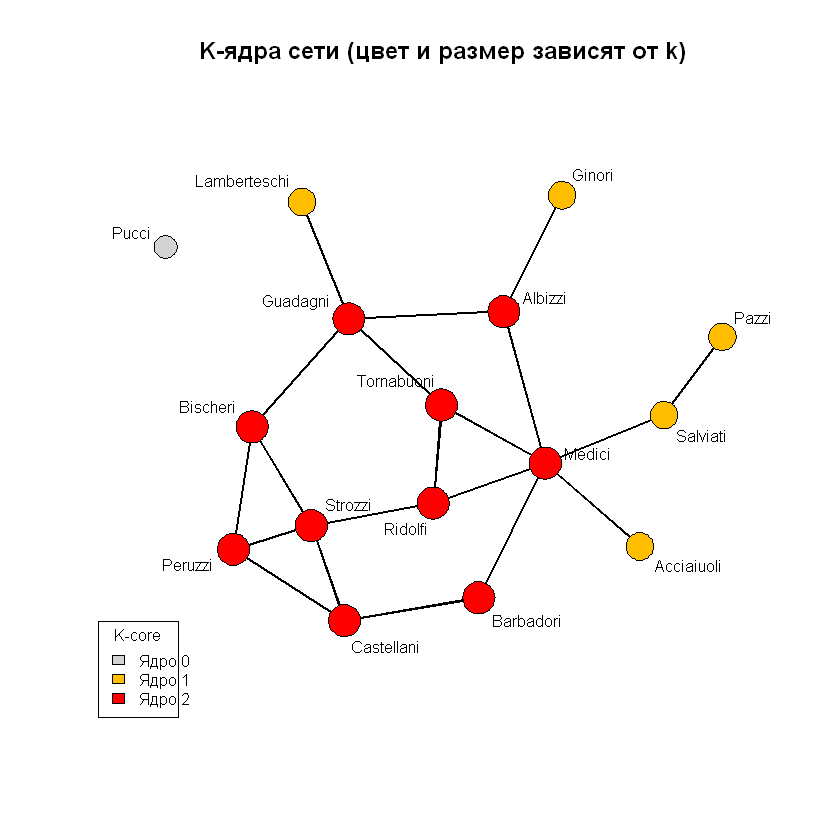

In [30]:
# k-ядра для каждого узла
cores <- coreness(g_ig)

# Результаты в консоль, группируя семьи по их k-ядру
cat("Результаты разбиения на k-ядра:\n")
for (k in sort(unique(cores), decreasing = TRUE)) 
{
  families <- V(g_ig)$name[cores == k]
  cat(sprintf("Ядро %d (размер %d): %s\n", k, length(families), paste(families, collapse = ", ")))
}

# Визуализация
unique_cores <- sort(unique(cores))
color_palette <- colorRampPalette(c("lightgray", "gold", "orange", "red"))(length(unique_cores))
v_colors_core <- color_palette[as.factor(cores)]

gplot(net, gmode = "graph", 
      mode = "fruchtermanreingold",
      displaylabels = TRUE, 
      label.cex = 0.8,
      vertex.col = v_colors_core,
      vertex.cex = 1 + cores * 0.2,
      main = "K-ядра сети (цвет и размер зависят от k)")

# Легенда
legend("bottomleft", legend = paste("Ядро", unique_cores), 
       fill = color_palette, title = "K-core", cex = 0.8, bg = "white")

**Вывод:**
В ходе анализа сеть была разбита на k-ядра, что позволило выявить её иерархическую структуру:
* 2-ядро (плотное ядро) включает 10 семей (Albizzi, Barbadori, Bischeri, Castellani, Guadagni, Medici, Peruzzi, Ridolfi, Strozzi, Tornabuoni). Это наиболее влиятельная и сплоченная группа, где каждая семья имеет как минимум две связи внутри этого круга.
* 1-ядро (периферия) состоит из 5 семей (Acciaiuoli, Ginori, Lamberteschi, Pazzi, Salviati). Они связаны с основной сетью, но не имеют достаточной плотности связей внутри своей группы.
* 0-ядро (изолят) представлено семьей Pucci, которая не имеет брачных связей с остальными семьями в данном датасете.

Максимальное значение k=2 указывает на то, что сеть не обладает сверхплотными кликами (где каждый связан с каждым), но имеет ярко выраженный устойчивый центр.

**Задание 5.** С помощью библиотеки igraph исследовать алгоритмы обнаружения сообществ (Вариант 2: Spinglass, Walktrap, Label propagation). Кратко объяснить суть каждого алгоритма. Вывести значение модулярности и отобразить полученные сообщества. Сделать выводы.

**Краткая теория алгоритмов:**
*   **Spinglass (Спиновое стекло)** — заимствован из физики. Представляет сеть как систему частиц (спинов), которые могут находиться в разных состояниях. Алгоритм ищет такое состояние, при котором энергия системы минимальна, что соответствует оптимальному разделению на сообщества.
*   **Walktrap (Случайные блуждания)** — основан на идее, что при случайном блуждании по сети "путник" будет дольше задерживаться внутри плотных сообществ и реже переходить между ними. Алгоритм итеративно объединяет узлы, между которыми чаще происходят блуждания.
*   **Label propagation (Распространение меток)** — очень быстрый алгоритм. Сначала каждой вершине присваивается уникальная метка. Затем на каждом шаге каждый узел принимает метку, которая чаще всего встречается у его соседей. Процесс повторяется, пока метки не стабилизируются.

**Модулярность** — это метрика (от -0.5 до 1), которая показывает, насколько хорошо алгоритм разбил сеть на сообщества. Значения выше 0.3 считаются хорошими, а выше 0.5 — отличными.

Модулярность Spinglass: 0.3975 
Модулярность Walktrap: 0.3975 
Модулярность Label propagation: 0.3975 

Сообщества:
Community sizes
1 2 3 4 
4 4 5 2 


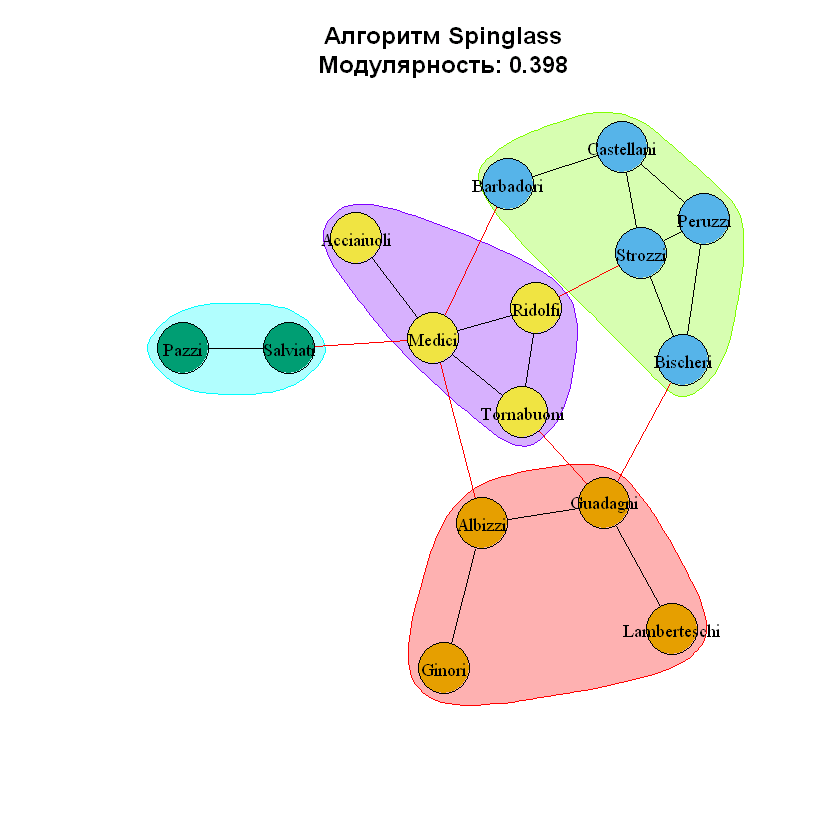

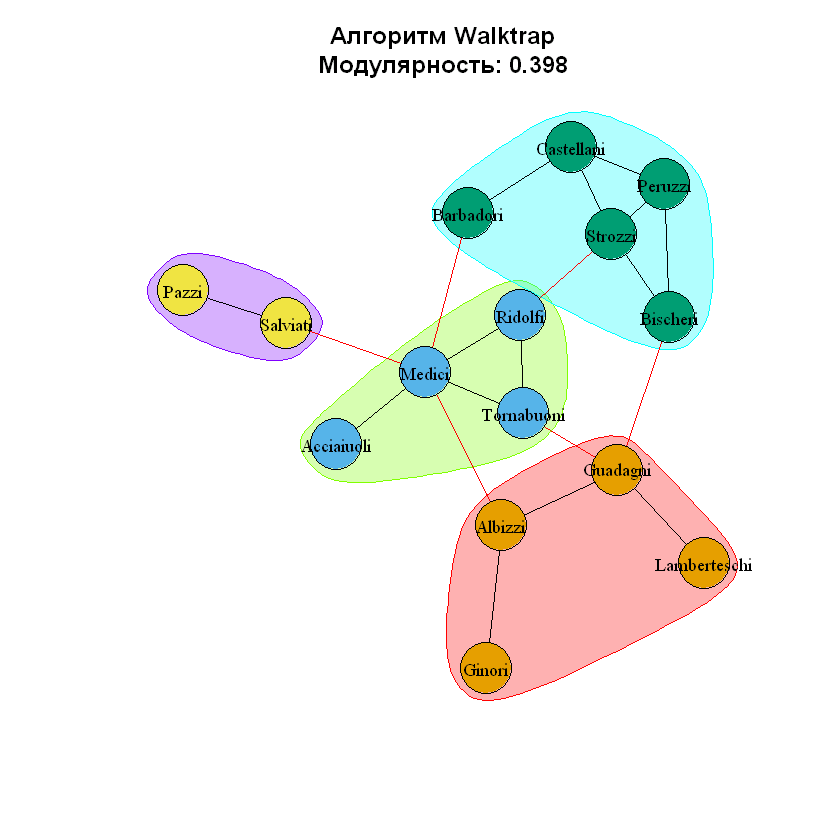

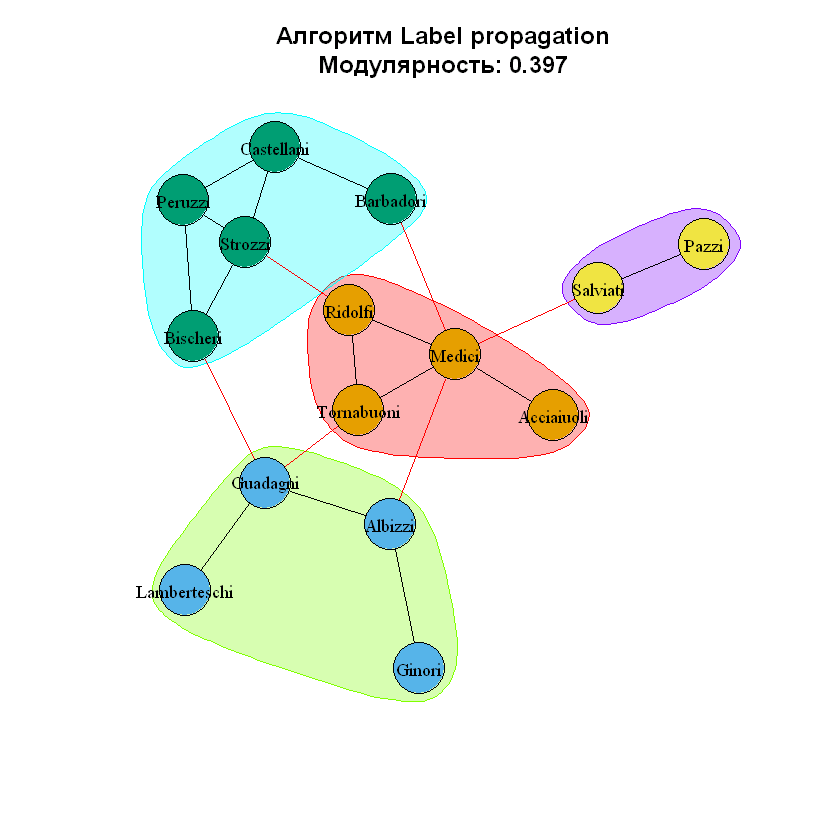

In [36]:
# Убрать изолированные узлы
g_comm <- delete_vertices(g_ig, V(g_ig)[degree(g_ig) == 0])

# Три алгоритма для графа
comm_spin <- cluster_spinglass(g_comm)
comm_walk <- cluster_walktrap(g_comm)
comm_label <- cluster_label_prop(g_comm)

# Модулярность для каждого
mod_spin <- modularity(comm_spin)
mod_walk <- modularity(comm_walk)
mod_label <- modularity(comm_label)

# Результаты в консоль
cat("Модулярность Spinglass:", round(mod_spin, 4), "\n")
cat("Модулярность Walktrap:", round(mod_walk, 4), "\n")
cat("Модулярность Label propagation:", round(mod_label, 4), "\n\n")

# Состав сообществ
cat("Сообщества:\n")
print(sizes(comm_walk))

# Визуализация
# График 1: Spinglass
plot(comm_spin, g_comm, 
     main=paste("Алгоритм Spinglass\nМодулярность:", round(mod_spin, 3)), 
     vertex.label.cex=0.9,  # Размер шрифта подписей
     vertex.size=20,        # Размер кружков
     edge.arrow.size=0.5,
     vertex.label.color="black")

# График 2: Walktrap
plot(comm_walk, g_comm, 
     main=paste("Алгоритм Walktrap\nМодулярность:", round(mod_walk, 3)), 
     vertex.label.cex=0.9, 
     vertex.size=20, 
     edge.arrow.size=0.5,
     vertex.label.color="black")

# График 3: Label propagation
plot(comm_label, g_comm, 
     main=paste("Алгоритм Label propagation\nМодулярность:", round(mod_label, 3)), 
     vertex.label.cex=0.9, 
     vertex.size=20, 
     edge.arrow.size=0.5,
     vertex.label.color="black")

**Вывод по пункту 5 (Анализ сообществ):**

В ходе работы были применены три алгоритма обнаружения сообществ. Значения модулярности оказались идентичными:
*   Spinglass: 0.398
*   Walktrap: 0.398
*   Label propagation: 0.398

Значение модулярности около 0.4 является хорошим показателем, что свидетельствует о наличии выраженной кластерной структуры, но при этом плотность связей между кластерами все еще достаточно высока.

**Анализ полученных сообществ (на примере Walktrap/Spinglass):**
Все три алгоритма выделили 4 стабильных сообщества:
1.  **Центральный кластер (желтый/синий):** Семьи *Medici, Ridolfi, Tornabuoni, Acciaiuoli*. Это ядро власти, где Медичи выступают главным хабом, связывающим этот кластер с остальными.
2.  **Кластер конкурентов (красный):** Семьи *Albizzi, Ginori, Guadagni, Lamberteschi*. Альбицци исторически были главными соперниками Медичи, и алгоритм четко выделил их в отдельно.
3.  **Северный/Восточный кластер (зеленый/бирюзовый):** Семьи *Strozzi, Bischeri, Peruzzi, Castellani, Barbadori*.
4.  **Периферийный кластер (фиолетовый):** Семьи *Pazzi, Salviati*. Они держатся особняком, связаны между собой и имеют лишь по одной связи с центральным кластером (через Медичи и Сальвиати).

**Сравнение алгоритмов:**
Spinglass и Walktrap показали абсолютно идентичное разбиение. Это доказывает устойчивость структуры сети. Label propagation (самый быстрый алгоритм) также пришел к тому же результату, но распределил цвета кластеров иначе. Высокая сходимость разных алгоритмов подтверждает, что данные кластеры реальны, а не являются артефактом конкретного математического метода.

**Задание 6.** Из файла `ceo.csv` извлечь матрицу инцидентности с помощью соответствующих функций. Отобразить полученную матрицу.

In [47]:
ceo_raw <- read.csv("ceo.csv", check.names = FALSE)

# Преобразование в матрицу и вывод на экран
ceo_matrix <- as.matrix(ceo_raw)
print(ceo_matrix)

      0 0 1 1 0 0 0 0 1 0 0 0 0 0 0
 [1,] 0 0 1 0 1 0 1 0 0 0 0 0 0 0 0
 [2,] 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0
 [3,] 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1
 [4,] 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0
 [5,] 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0
 [6,] 0 0 1 1 0 0 0 0 0 1 1 0 0 0 0
 [7,] 0 0 0 1 0 0 1 0 0 1 0 0 0 0 0
 [8,] 1 0 0 1 0 0 0 1 0 1 0 0 0 0 0
 [9,] 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0
[10,] 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0
[11,] 0 0 0 1 0 0 1 0 0 0 0 0 0 0 0
[12,] 0 0 1 1 1 0 0 0 1 0 0 0 0 0 0
[13,] 0 1 1 1 0 0 0 0 0 0 1 1 1 0 1
[14,] 0 1 1 0 0 1 0 0 0 0 0 0 1 0 1
[15,] 0 1 1 0 0 1 0 1 0 0 0 0 0 1 0
[16,] 0 1 1 0 1 0 0 0 0 0 1 1 0 0 1
[17,] 0 0 0 1 0 0 0 0 1 0 0 1 1 0 1
[18,] 1 0 1 1 0 0 1 0 1 0 0 0 0 0 0
[19,] 0 1 1 1 0 0 0 0 0 0 1 0 0 0 1
[20,] 0 0 1 1 0 0 0 1 0 0 0 0 0 0 0
[21,] 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1
[22,] 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1
[23,] 1 0 1 1 0 1 0 0 0 0 0 0 0 0 1
[24,] 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0
[25,] 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0


**Задание 7.** Отобразить сеть в виде биграфа.

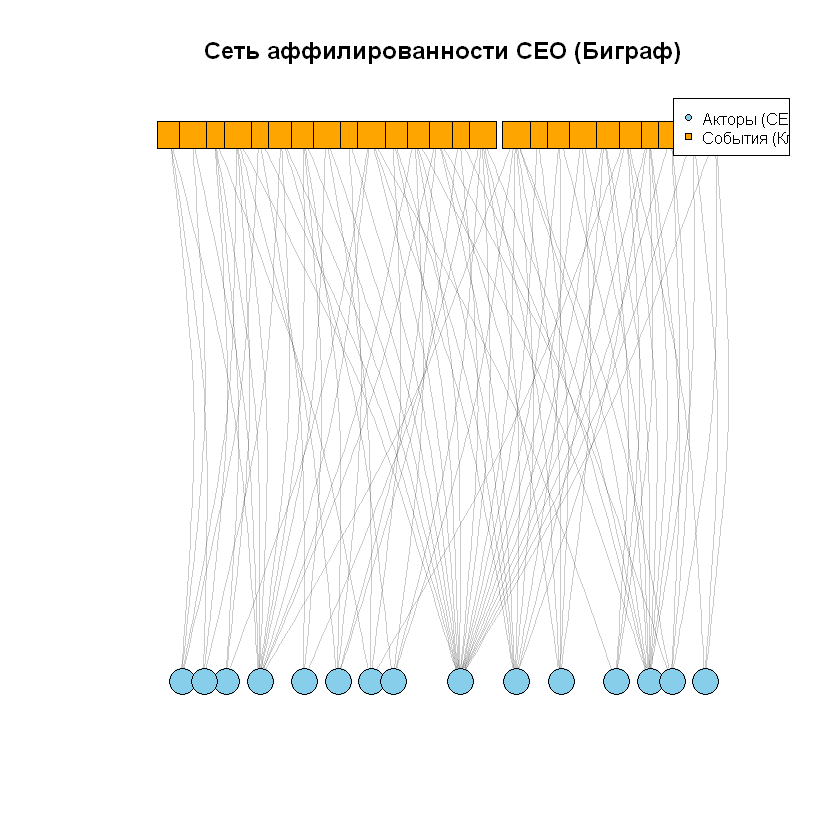

In [49]:
#Создание объекта биграфа
g_bip <- graph_from_biadjacency_matrix(ceo_matrix)

V(g_bip)$type <- bipartite_mapping(g_bip)$type
V(g_bip)$color <- ifelse(V(g_bip)$type, "skyblue", "orange")
V(g_bip)$shape <- ifelse(V(g_bip)$type, "circle", "square")

# Отображание биграфа
plot(g_bip, 
     vertex.label = NA,       
     vertex.size = 10,
     edge.color = rgb(0,0,0,0.2),
     edge.width = 0.8,
     edge.curved = 0.1,
     layout = layout_as_bipartite, 
     main = "Сеть аффилированности CEO (Биграф)")

# Легенда (сдвинем ее вправо, чтобы не перекрывала узлы)
legend("topright", legend=c("Акторы (CEO)", "События (Клубы)"),
       pch=c(21, 22), pt.bg=c("skyblue", "orange"), cex=0.8, bg="white")

**Задание 8.** Отобразить сеть в виде гиперграфа и двойственного гиперграфа.

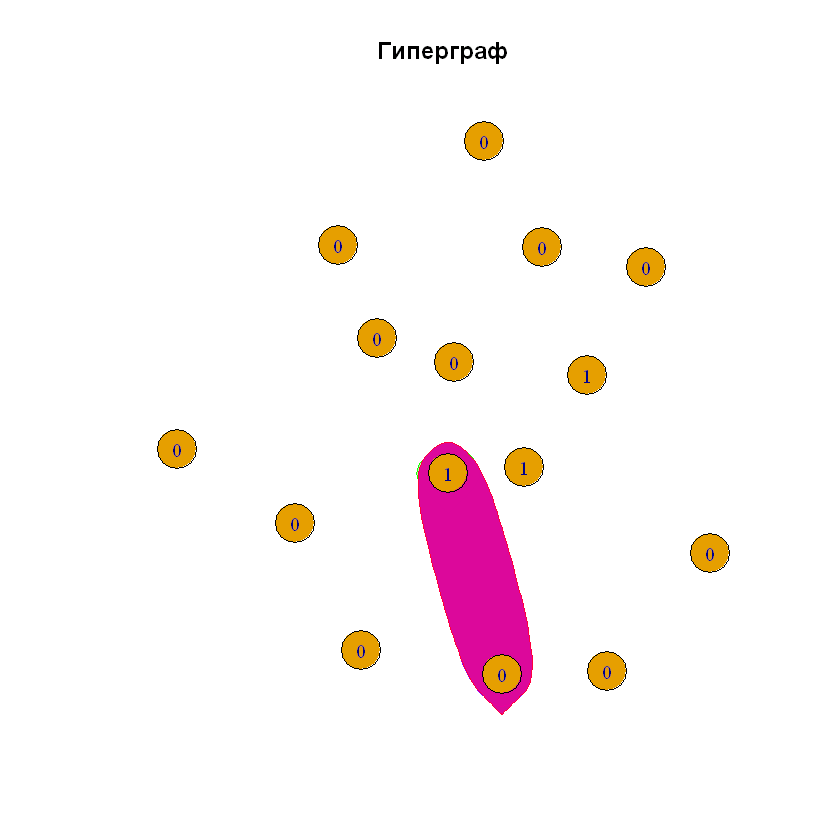

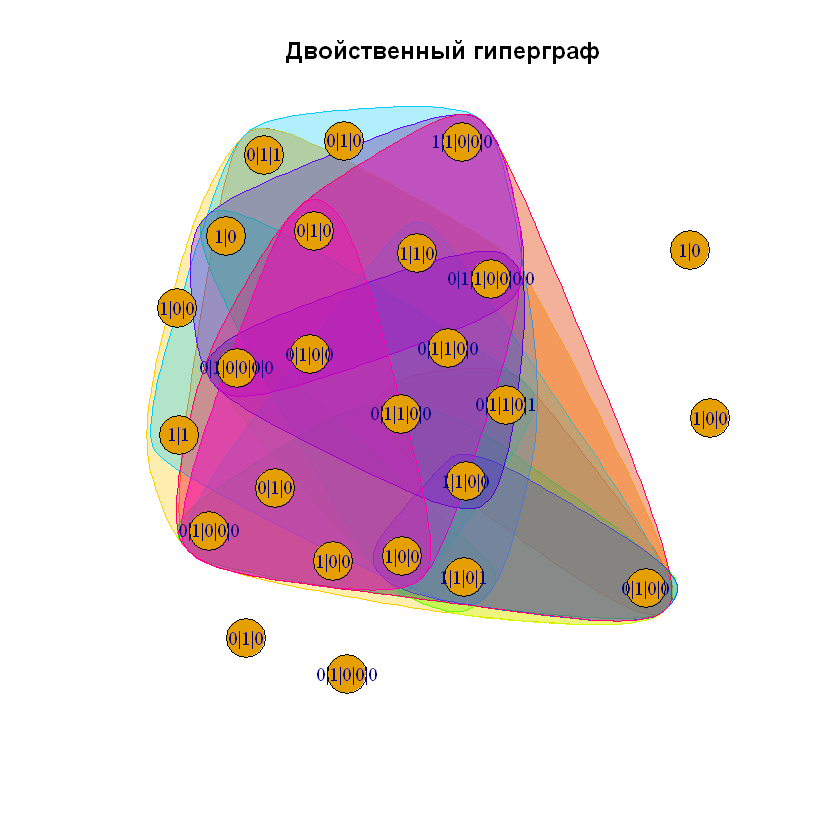

In [57]:
library(HyperG)

# Гиперграф из матрицы инцидентности
hg_alt <- hypergraph_from_incidence_matrix(ceo_matrix)
plot(hg_alt, main = "Гиперграф")

# Двойственный гиперграф
hg_alt_dual <- dual_hypergraph(hg_alt)
plot(hg_alt_dual, main = "Двойственный гиперграф")

**Задание 9.** Представить сеть аффилированности в виде двух одномодальных сетей: сеть совместного участия акторов и сеть перекрытия событий. Представить полученные сети в виде матриц и взвешенных графов. Сделать выводы.

      [,1] [,2] [,3] [,4] [,5] [,6] [,7] [,8] [,9] [,10] [,11] [,12] [,13]
 [1,]    0    1    1    1    1    1    1    0    1     1     1     2     1
 [2,]    1    0    1    1    1    1    0    0    1     1     0     1     2
 [3,]    1    1    0    1    2    1    0    0    1     2     0     1     3
 [4,]    1    1    1    0    2    1    0    0    1     1     0     1     2
 [5,]    1    1    2    2    0    1    0    0    1     2     0     1     2
 [6,]    1    1    1    1    1    0    2    2    1     1     1     2     3
 [7,]    1    0    0    0    0    2    0    2    0     0     2     1     1
 [8,]    0    0    0    0    0    2    2    0    0     0     1     1     1
 [9,]    1    1    1    1    1    1    0    0    0     2     0     2     1
[10,]    1    1    2    1    2    1    0    0    2     0     0     2     2
[11,]    1    0    0    0    0    1    2    1    0     0     0     1     1
[12,]    2    1    1    1    1    2    1    1    2     2     1     0     2
[13,]    1    2    3    2

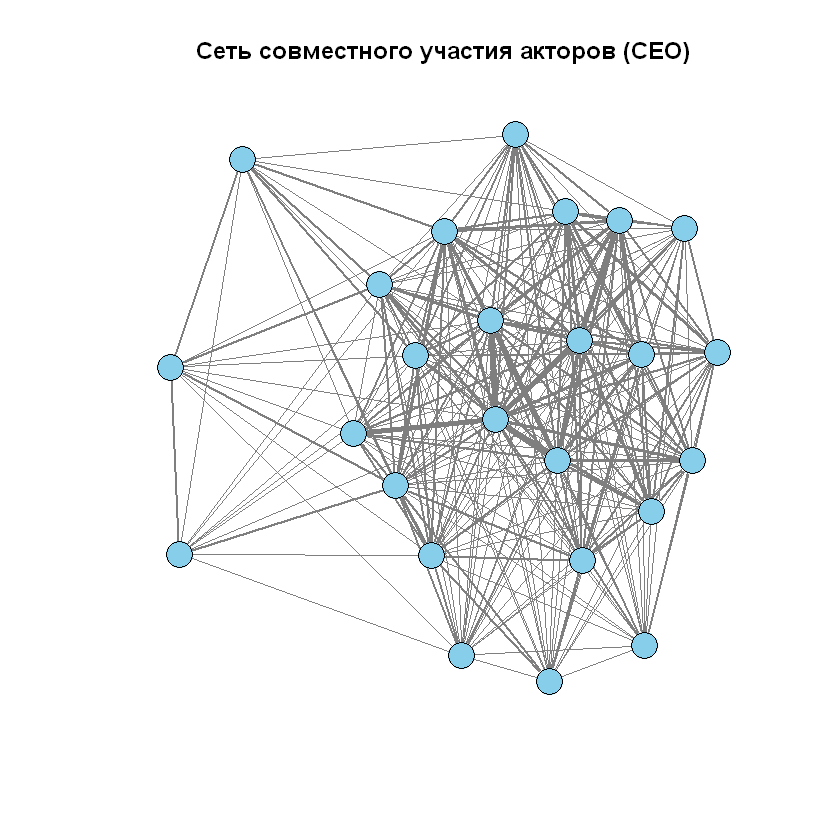

In [61]:
# Матрица совместного участия акторов (CEO x CEO)
# Умножение матрицы на её транспонированную версию
actor_matrix <- ceo_matrix %*% t(ceo_matrix)
diag(actor_matrix) <- 0 # убирание пятель

print(actor_matrix)

# Взвешенный граф совместного участия
g_actor <- graph_from_adjacency_matrix(actor_matrix, mode = "undirected", weighted = TRUE, diag = FALSE)

plot(g_actor,
     edge.width = E(g_actor)$weight, # Толщина ребра зависит от веса
     edge.color = "gray50",
     vertex.color = "skyblue",
     vertex.size = 10,
     vertex.label = NA,
     main = "Сеть совместного участия акторов (CEO)")

  0  0  1 1 0 0 0 0 1 0 0 0 0 0 0
0 0  0  2 3 0 1 1 1 1 1 0 0 0 0 1
0 0  0 11 2 1 3 0 1 1 0 3 3 3 2 6
1 2 11  0 7 3 4 2 3 4 1 4 4 4 3 8
1 3  2  7 0 1 1 3 2 3 3 3 2 2 0 4
0 0  1  3 1 0 0 1 0 1 0 1 1 0 0 1
0 1  3  4 1 0 0 0 1 0 0 0 0 1 1 3
0 1  0  2 3 1 0 0 0 1 1 0 0 0 0 0
0 1  1  3 2 0 1 0 0 0 1 0 0 0 1 1
1 1  1  4 3 1 0 1 0 0 0 0 1 1 0 1
0 1  0  1 3 0 0 1 1 0 0 1 0 0 0 0
0 0  3  4 3 1 0 0 0 0 1 0 2 1 0 3
0 0  3  4 2 1 0 0 0 1 0 2 0 2 0 3
0 0  3  4 2 0 1 0 0 1 0 1 2 0 1 3
0 0  2  3 0 0 1 0 1 0 0 0 0 1 0 0
0 1  6  8 4 1 3 0 1 1 0 3 3 3 0 0


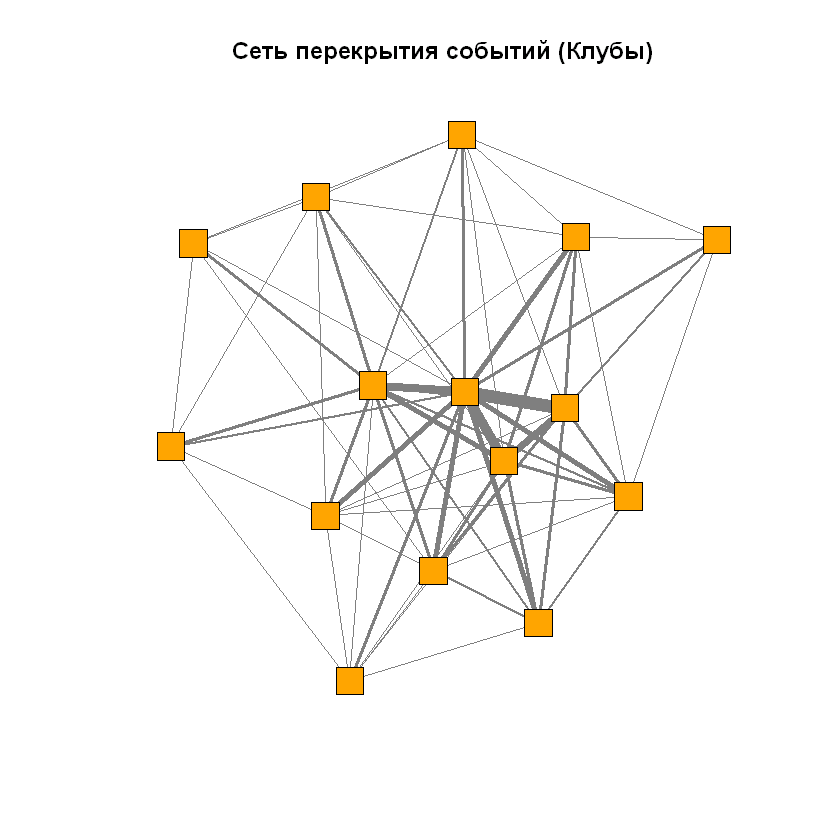

In [62]:
# Матрица перекрытия событий (Клубы x Клубы)
event_matrix <- t(ceo_matrix) %*% ceo_matrix
diag(event_matrix) <- 0 # убирание пятель

print(event_matrix)

# Взвешенный граф перекрытия событий
g_event <- graph_from_adjacency_matrix(event_matrix, mode = "undirected", weighted = TRUE, diag = FALSE)

plot(g_event,
     edge.width = E(g_event)$weight,
     edge.color = "gray50",
     vertex.color = "orange",
     vertex.shape = "square",
     vertex.size = 10,
     vertex.label = NA,
     main = "Сеть перекрытия событий (Клубы)")

**Вывод:**

В результате преобразования двудольной сети аффилированности были получены две одномодальные проекции:

1.  **Сеть совместного участия акторов (матрица 25x25):** 
    Связывает CEO, если они состоят в одних и тех же клубах. Матрица показывает, что веса связей (количество общих клубов) достигают 5. Граф визуально очень плотный: большинство акторов связаны друг с другом. При этом можно заметить несколько периферийных узлов (например, узлы 1, 8, 25), которые имеют меньше всего связей.

2.  **Сеть перекрытия событий (матрица 15x15):** 
    Связывает клубы, если в них состоят одни и те же люди. Здесь веса (количество общих участников) достигают максимума в 8 человек. Граф демонстрирует тесную связность всех организаций. На графике отчетливо видны "хабы" — клубы, которые имеют самые толстые ребра и связаны со всеми остальными.

**Общий вывод:** Обе проекции демонстрируют крайне высокую плотность. Тот факт, что многие акторы имеют вес 3, 4 и 5, означает, что их взаимодействие не случайно — они образуют устойчивое ядро, контролирующее основные институты. Сеть представляет собой классический пример закрытого элитного клуба, где пересечение интересов максимально.

**Задание 10.** Вычислить степень участия для каждого актора, а также среднее количество событий, с которыми актор аффилирован. Сделать выводы.

In [63]:
# Степень участия для каждого актора (сумма по строкам)
# Это количество клубов, в которых состоит каждый CEO
actor_degrees <- rowSums(ceo_matrix)

print(actor_degrees)

# Среднее количество событий на одного актора
mean_events <- mean(actor_degrees)
cat("\nСреднее количество событий на одного актора:", round(mean_events, 2), "\n")

 [1] 3 2 3 3 3 4 3 4 2 3 2 4 7 5 5 6 5 5 5 3 3 4 5 3 3

Среднее количество событий на одного актора: 3.8 


**Вывод:**

В ходе расчета была вычислена степень участия для каждого из 25 акторов. Значения распределились неравномерно: минимальное участие составляет 2 события, а максимальное — 7 событий. 

Среднее количество событий, с которыми аффилирован один актор, равно **3.8**. Это достаточно высокий показатель, который подтверждает тесную интеграцию бизнес-элит. В среднем каждый CEO состоит почти в 4 организациях, что обеспечивает высокую плотность сети и создает множество точек пересечения интересов. Наличие акторов с 6 и 7 связями свидетельствует о присутствии ярко выраженных "хабов" — наиболее влиятельных лиц, связывающих между собой различные клубы.

**Задание 11.** Вычислить размер и средний размер для каждого события. Сделать выводы.

In [64]:
# Размер каждого события (сумма по столбцам)
# Это количество CEO, состоящих в каждом клубе
event_sizes <- colSums(ceo_matrix)

print(event_sizes)

# Средний размер события
mean_event_size <- mean(event_sizes)
cat("\nСредний размер события (клуба):", round(mean_event_size, 2), "\n")

 0  0  1  1  0  0  0  0  1  0  0  0  0  0  0 
 3 11 21 11  3  4  4  4  5  3  4  5  5  3  9 

Средний размер события (клуба): 6.33 


**Вывод:**

В ходе расчетов был определен размер каждого из 15 событий (клубов). Результаты показали сильную неоднородность:
*   Минимальный размер клуба составляет 3 человека.
*   Максимальный размер клуба достигает 21 человека.
*   Средний размер события (клуба) равен **6.33**.

Структура клубов сильно централизована. Наличие одного гигантского клуба (21 участник) и двух крупных (по 11 участников) создает мощные хабы, через которые связана большая часть CEO. Остальные клубы (размером 3–5 человек) представляют собой более узкие, закрытые группы по интересам. Средний размер в 6.33 человека говорит о том, что типичный клуб — это небольшая группа, но именно крупные организации играют ключевую роль в объединении элиты в единую сеть.

**Задание 12.** Вычислить плотность для отношения совместного участия акторов и отношения перекрытия. Проинтерпретировать полученные значения.

In [65]:
# Плотность сети совместного участия акторов (CEO)
density_actor <- edge_density(g_actor)

# Плотность сети перекрытия событий (Клубы)
density_event <- edge_density(g_event)

cat("Плотность сети совместного участия акторов:", round(density_actor, 4), "\n")
cat("Плотность сети перекрытия событий:", round(density_event, 4), "\n")

Плотность сети совместного участия акторов: 0.8633 
Плотность сети перекрытия событий: 0.6286 


**Вывод:**

В ходе расчетов были получены следующие значения плотности:
*   **Плотность сети совместного участия акторов: 0.8633 (86.3%)**
*   **Плотность сети перекрытия событий: 0.6286 (62.8%)**

**Интерпретация:**
1.  **Сеть акторов (0.8633):** Значение, близкое к 1, означает, что бизнес-элита представляет собой крайне сплоченную и закрытую группу. Практически каждый CEO связан с большинством остальных через совместное участие в клубах. Это говорит о высочайшем уровне взаимосвязи и отсутствии "одиночек" в данной выборке.
2.  **Сеть событий (0.6286):** Плотность клубов также высока (более 60%), но ниже, чем у акторов. Это объясняется тем, что события (клубы) имеют разный масштаб: маленькие клубы (на 3 человека) с меньшей вероятностью пересекаются с другими, чем гигантские хабы (на 21 человека).

**Задание 13.** Определить диаметр сети аффилированности.

In [67]:
# Диаметр для биграфа
diam_bip <- diameter(g_bip, directed = FALSE, unconnected = TRUE)

cat("Диаметр сети аффилированности (биграфа):", diam_bip, "\n")

Диаметр сети аффилированности (биграфа): 5 


**Задание 14.** Для каждых пар событий определить (логарифм) отношение шансов. Сделать выводы.

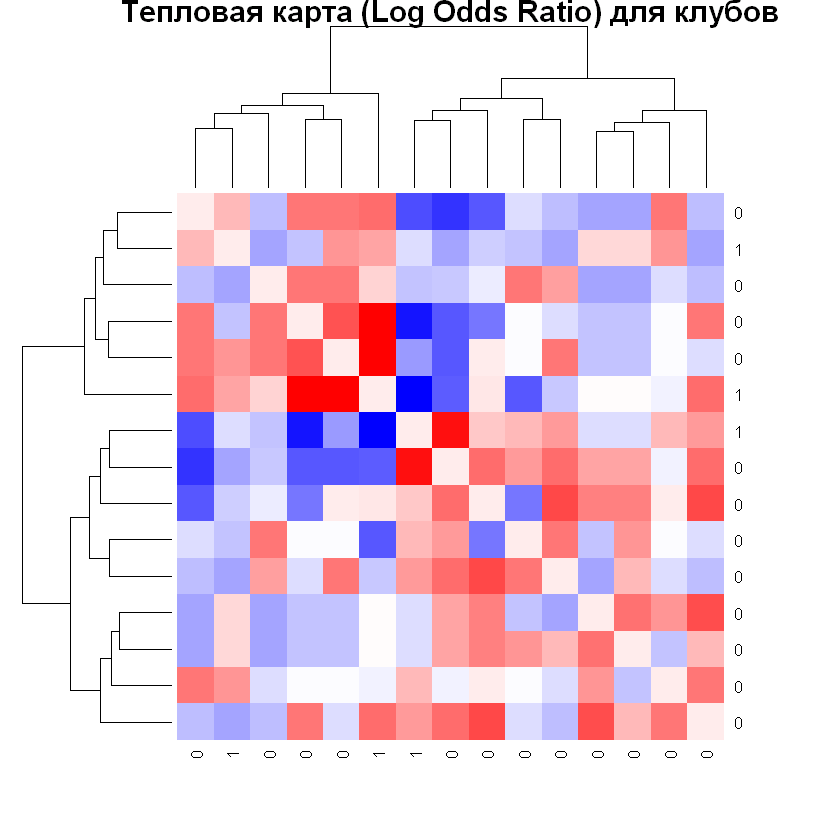

In [69]:
# Количество событий (клубов)
num_events <- ncol(ceo_matrix)

# Пустая матрица для хранения логарифмов отношения шансов
log_or_matrix <- matrix(0, nrow = num_events, ncol = num_events)
rownames(log_or_matrix) <- colnames(ceo_matrix)
colnames(log_or_matrix) <- colnames(ceo_matrix)

# Двойной цикл по всем возможным парам клубов
for (i in 1:(num_events - 1)) 
{
  for (j in (i + 1):num_events) 
  {
    event_i <- ceo_matrix[, i]
    event_j <- ceo_matrix[, j]
    
    # Таблица сопряженности 2x2 (a, b, c, d)
    a <- sum(event_i == 1 & event_j == 1) # В обоих клубах
    b <- sum(event_i == 1 & event_j == 0) # Только в первом
    c <- sum(event_i == 0 & event_j == 1) # Только во втором
    d <- sum(event_i == 0 & event_j == 0) # Ни в одном
    
    a <- a + 0.5
    b <- b + 0.5
    c <- c + 0.5
    d <- d + 0.5
    
    # Логарифм
    log_or <- log((a * d) / (b * c))

    log_or_matrix[i, j] <- log_or
    log_or_matrix[j, i] <- log_or
  }
}

# Тепловая карта для наглядности
heatmap(log_or_matrix, symm = TRUE, 
        main = "Тепловая карта (Log Odds Ratio) для клубов",
        col = colorRampPalette(c("blue", "white", "red"))(100))

**Вывод:**

Для каждой пары событий был рассчитан логарифм отношения шансов (Log Odds Ratio), результаты которого представлены в виде тепловой карты с иерархической кластеризацией (дендрограммами).

*   **Красные области (положительные значения)** указывают на то, что клубы имеют общих участников значительно чаще, чем можно было бы ожидать случайно. На карте видны крупные красные блоки — это группы клубов, которые формируют единую экосистему, где элита пересекается наиболее плотно.
*   **Синие области (отрицательные значения)** показывают пары клубов, которые практически не имеют общих членов. Наличие таких "синих крестов" свидетельствует о том, что в сети аффилированности существуют отдельные, возможно, конкурирующие или идеологически разные группы (фракции).
*   **Дендрограммы** (деревья сверху и слева) наглядно демонстрируют иерархию сходства: алгоритм автоматически сгруппировал клубы со схожим составом участников в отдельные кластеры.

Сеть аффилированности не является монолитной. Несмотря на общую высокую плотность, в ней четко прослеживаются несколько изолированных подгрупп клубов, которые имеют разный состав участников и, вероятно, представляют разные сферы влияния.

## Общий вывод по работе

В ходе практической работы были освоены методы анализа сетей с использованием языка R и библиотек `sna`, `igraph` и `HyperG`. 

1. **Анализ подгрупп (сеть флорентийских семей):** С помощью поиска мостов, точек сочленения и k-ядер было доказано, что сеть имеет ярко выраженный центр. Семья Медичи выступает ключевым хабом, без которого сеть теряет связность. Алгоритмы обнаружения сообществ (Spinglass, Walktrap, Label propagation) показали стабильную модулярность (~0.4) и выделили исторически подтвержденные политические кластеры (Медичи, Альбицци, Строцци).
2. **Анализ сетей аффилированности (CEO и клубы):** Сеть была успешно представлена в виде биграфа, а также преобразована в одномодальные проекции (совместное участие и перекрытие событий). 
3. **Метрики аффилированности:** Расчет плотности показал экстремально высокую сплоченность элиты (86% для акторов). Анализ степеней участия выявил наличие активных "хабов" (до 7 клубов на человека). Тепловая карта на основе логарифма отношения шансов подтвердила наличие как тесно связанных клубов, так и изолированных фракций.

**Заключение:** Использование математических пакетов для сетевого анализа позволяет выявлять скрытые структуры власти, неформальные связи и иерархии в социальных системах, что имеет огромное практическое значение для социологии, политологии и бизнес-аналитики.